#yfinance is a Python library used to download financial market data from Yahoo Finance.

It allows you to collect stock prices, historical market data, dividends, company information, and other financial data directly into Python.

!pip install yfinance


In [1]:
%pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# import the library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor


In [34]:
#The code fetches historical price data for Bitcoin, Ethereum, Tether, and Binance Coin for the past 1 years and keeps only the Close and Volume columns for each of these cryptocurrencies.
#This cleaned data can then be used for further analysis or machine learning tasks, such as predicting future prices.


btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='1y')
prices1.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='1y')
prices2.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='1y')
prices3.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='1y')
prices4.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

In [4]:
#The parameters lsuffix and rsuffix in the join method are used to add suffixes to overlapping column names when joining two DataFrames
# This is necessary to avoid column name conflicts when the two DataFrames have columns with the same name.

p1 = prices1.join(prices2, lsuffix = ' (BTC)', rsuffix = ' (ETH)')
p2 = prices3.join(prices4, lsuffix = ' (USDT)', rsuffix = ' (BNB)')
data = p1.join(p2, lsuffix = '_', rsuffix = '_')

In [5]:
data.sample(5)

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2023-11-12 00:00:00+00:00,37054.519531,11545715999,2045.187012,7951011698,1.000143,34090921591,247.640015,758715918
2023-06-15 00:00:00+00:00,25576.394531,15837384409,1665.519775,7328564880,0.999183,26724033220,236.280685,502420772
2024-04-17 00:00:00+00:00,61276.691406,41915247049,2984.727539,17711869375,0.999994,71118551643,534.416016,1411927485
2025-04-28 00:00:00+00:00,94978.750000,32363449569,1798.851807,17043640437,1.000267,71418678616,606.364990,1478956158
2024-03-07 00:00:00+00:00,66925.484375,46989543159,3874.347656,22457177587,1.001401,95225950701,475.290649,3328990543


In [6]:
data.shape

(1827, 8)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-19 00:00:00+00:00 to 2026-10-19 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1827 non-null   float64
 1   Volume (BTC)   1827 non-null   int64  
 2   Close (ETH)    1827 non-null   float64
 3   Volume (ETH)   1827 non-null   int64  
 4   Close (USDT)   1827 non-null   float64
 5   Volume (USDT)  1827 non-null   int64  
 6   Close (BNB)    1827 non-null   float64
 7   Volume (BNB)   1827 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.5 KB


In [8]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03
mean,58977.470500,3.459656e+10,2505.231545,1.756234e+10,0.999969,6.764146e+10,511.186213,1.624951e+09
std,29880.806350,2.059293e+10,877.090484,1.184787e+10,0.000663,4.224546e+10,219.729182,1.087343e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29412.204102,2.028428e+10,1810.192871,9.419950e+09,0.999660,3.928935e+10,304.748932,9.030619e+08
50%,60945.812500,3.010805e+10,2372.201904,1.495405e+10,1.000060,5.793143e+10,556.390869,1.517608e+09
75%,82547.617188,4.255977e+10,3120.746948,2.171727e+10,1.000283,8.340095e+10,642.500763,2.009017e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


In [9]:
data.isnull().sum()

Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

# Exploratory Data Analysis

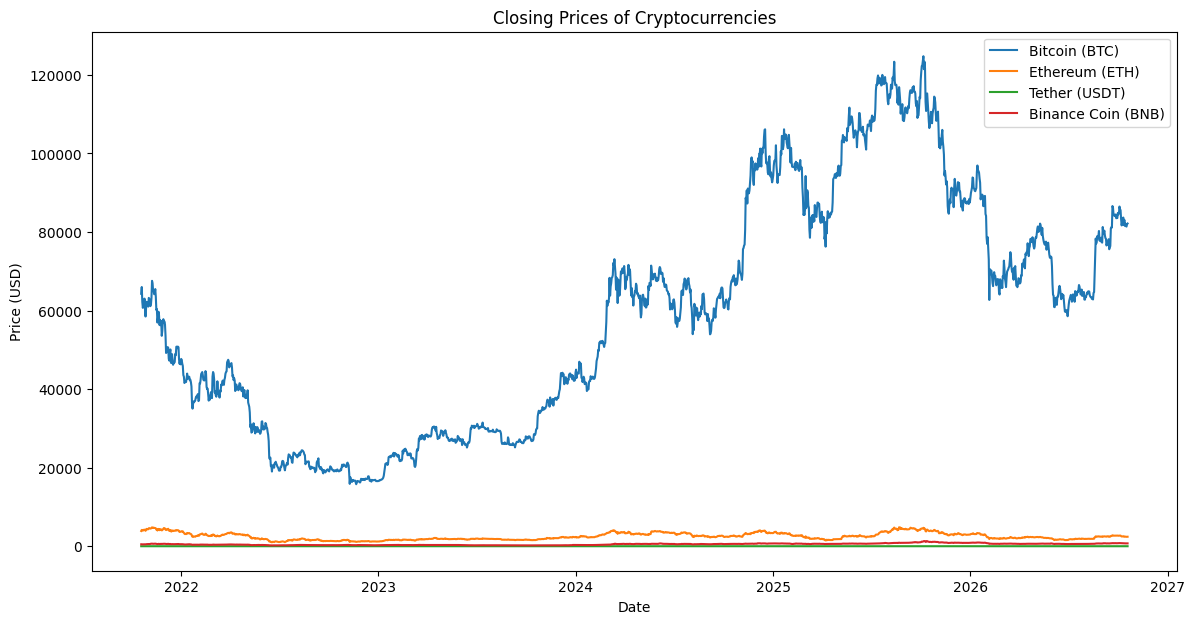

In [11]:
#Visualize the Closing Prices
# create a line plot to visualize the closing prices of all four cryptocurrencies over time:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Close (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index,data['Close (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index,data['Close (USDT)'],label='Tether (USDT)')
plt.plot(data.index,data['Close (BNB)'],label='Binance Coin (BNB)')
plt.title('Closing Prices of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

<Axes: xlabel='Date'>

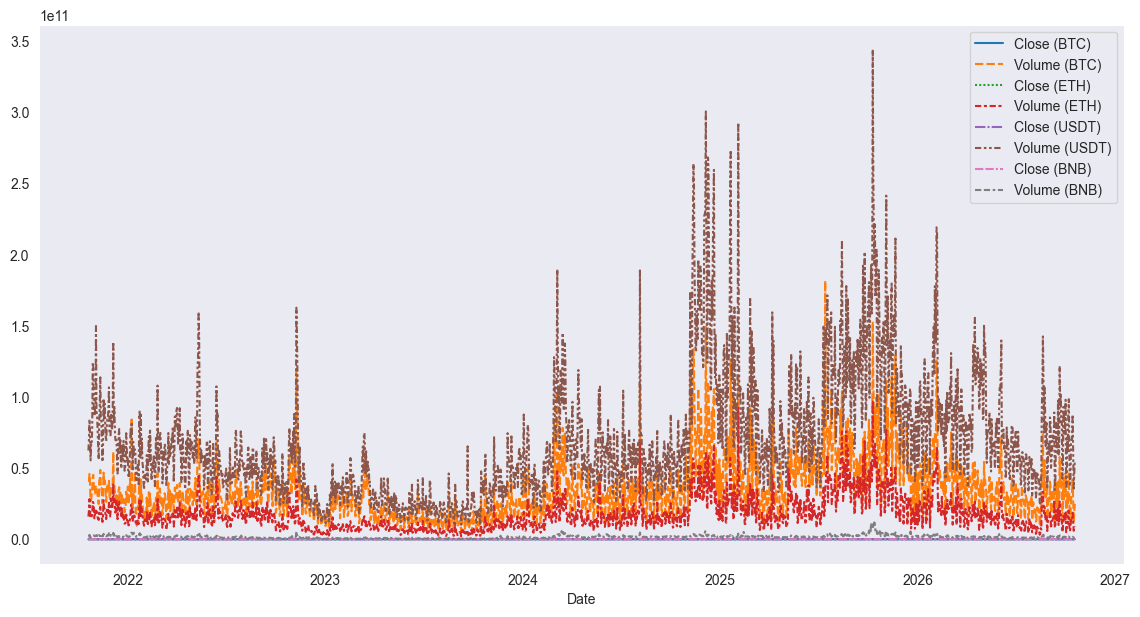

In [12]:
plt.figure(figsize = (14, 7))
sns.set_style('dark')
sns.lineplot(data=data)

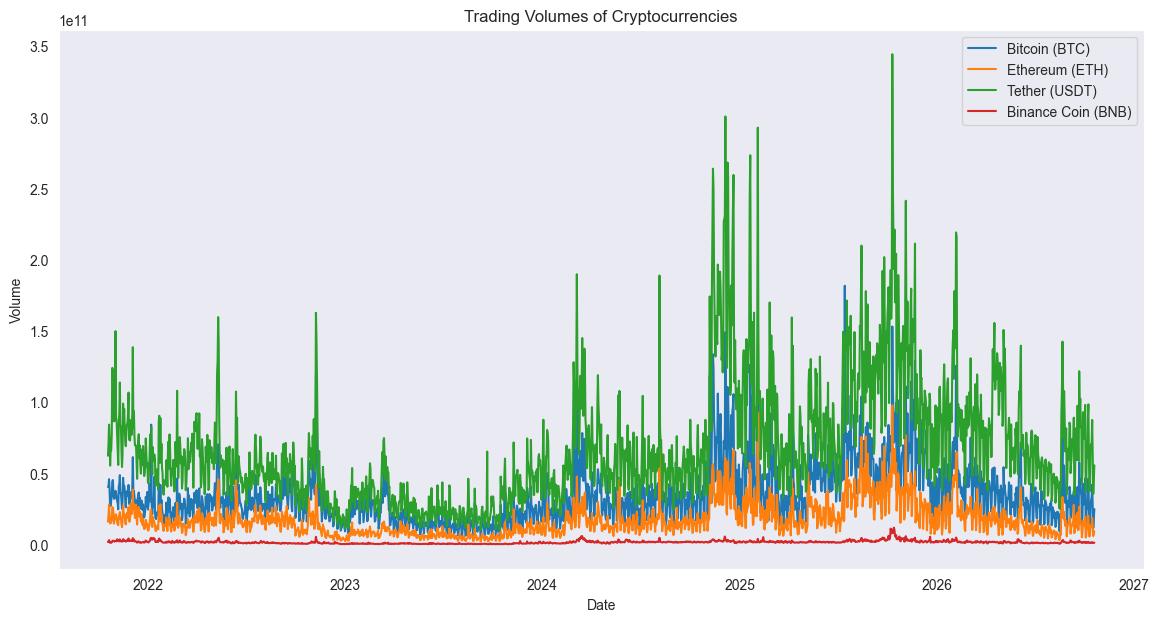

In [13]:
# Visualize the Trading Volumes
#Let's visualize the trading volumes of all four cryptocurrencies:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()


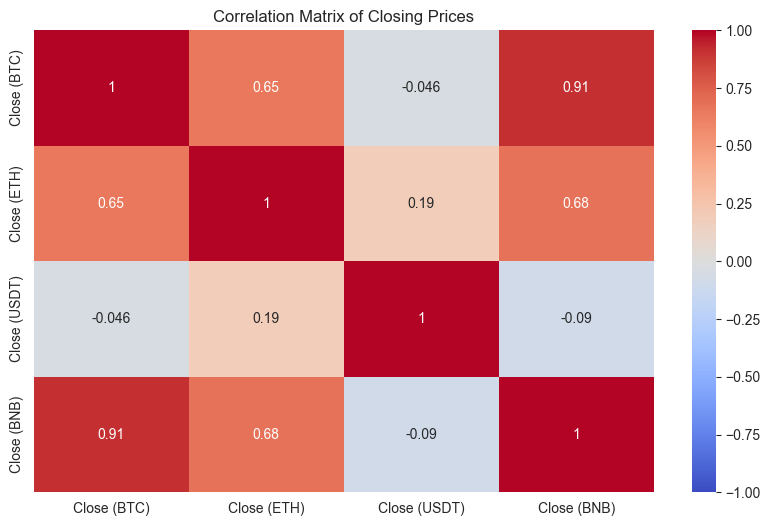

In [14]:
 #Correlation Analysis
#We'll analyze the correlation between the closing prices of the cryptocurrencies:
# Calculate the correlation matrix
corr_matrix = data[['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Closing Prices')
plt.show()

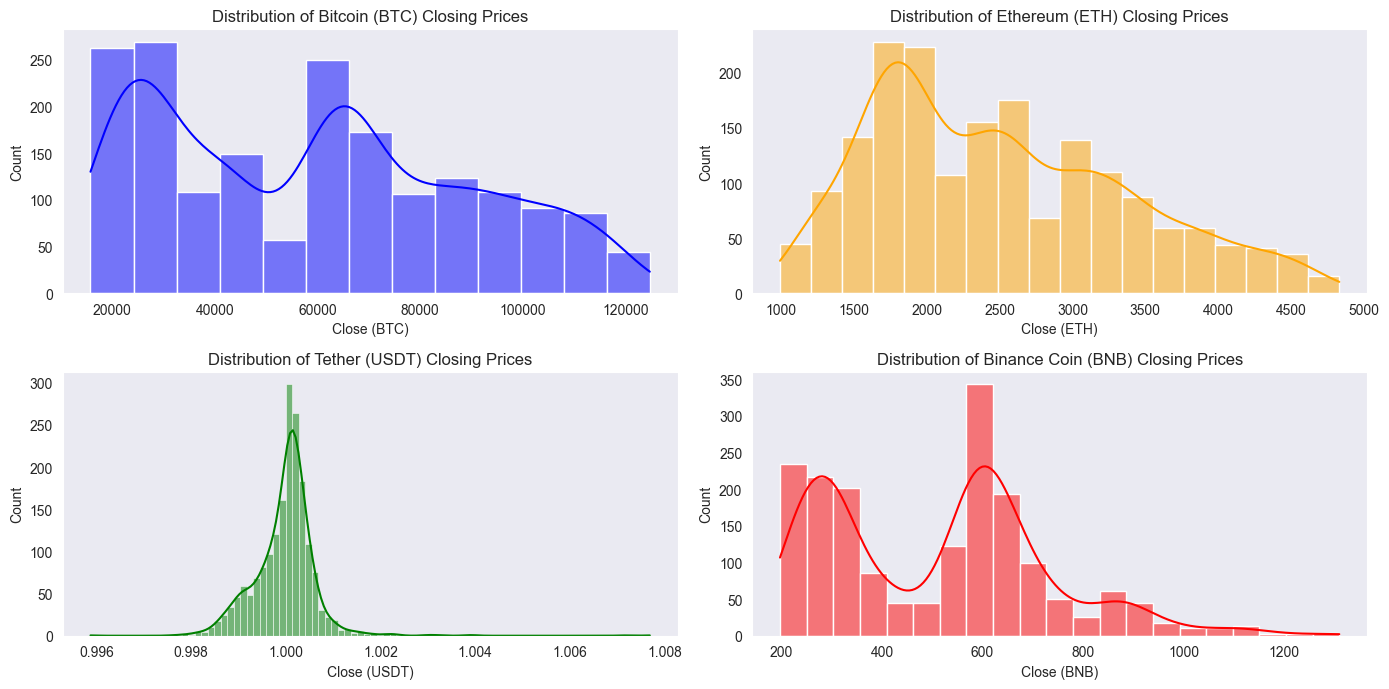

In [15]:
# Distribution of Closing Prices
#Let's plot the distribution of closing prices for each cryptocurrency:
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()

array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

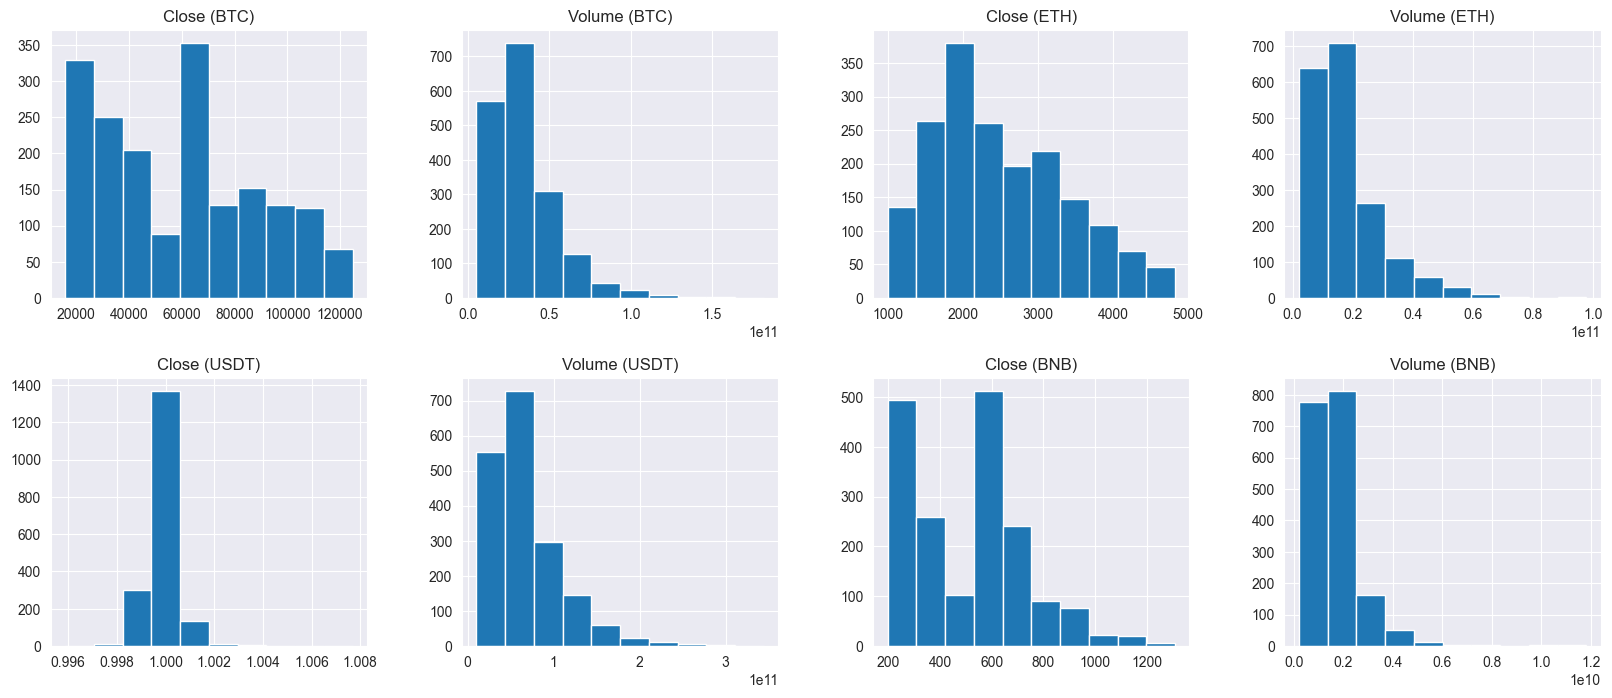

In [16]:
#distribution of closing prices or volumes
data.hist(figsize=(20, 8), layout=(2, 4))

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

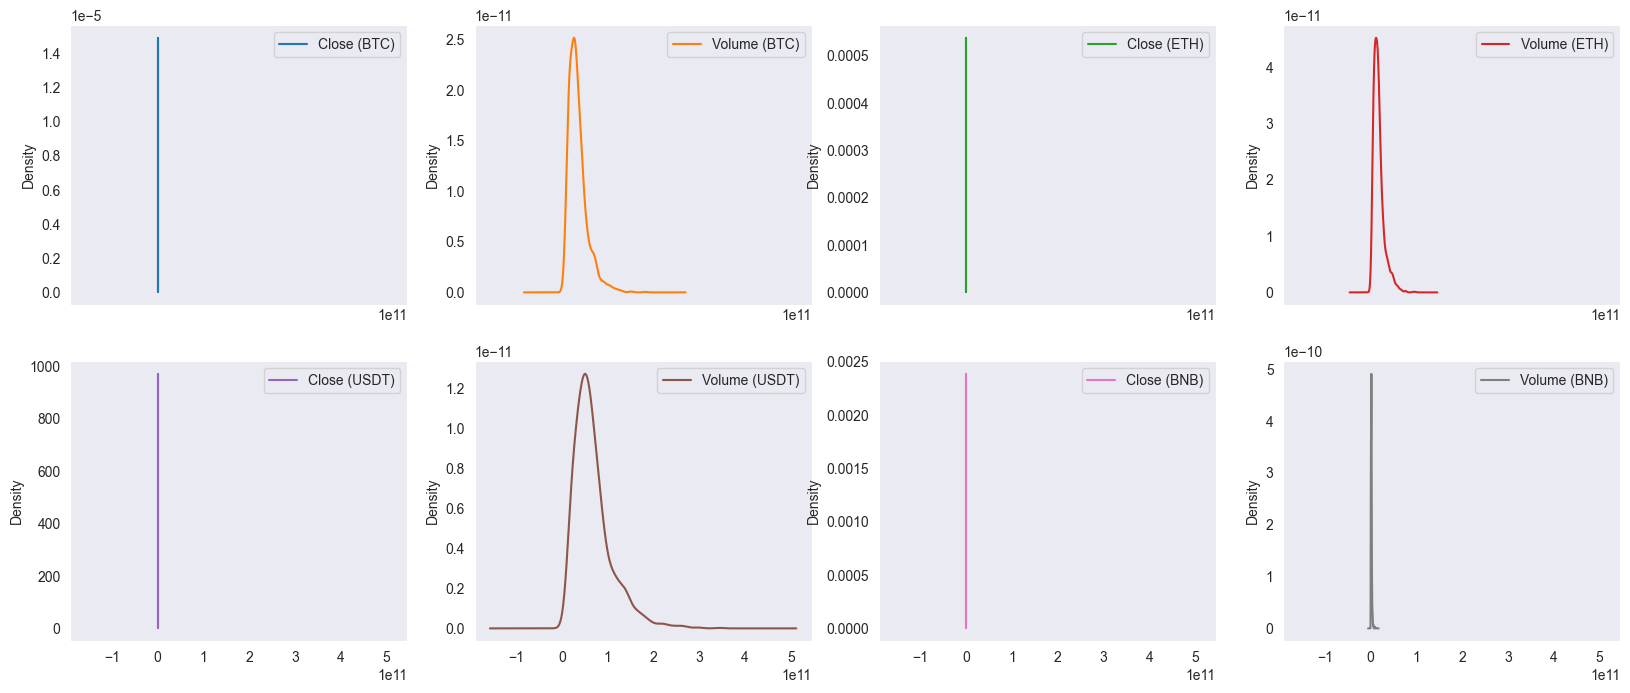

In [17]:
data.plot(kind = "kde", subplots = True, layout = (2, 4), figsize = (20, 8))

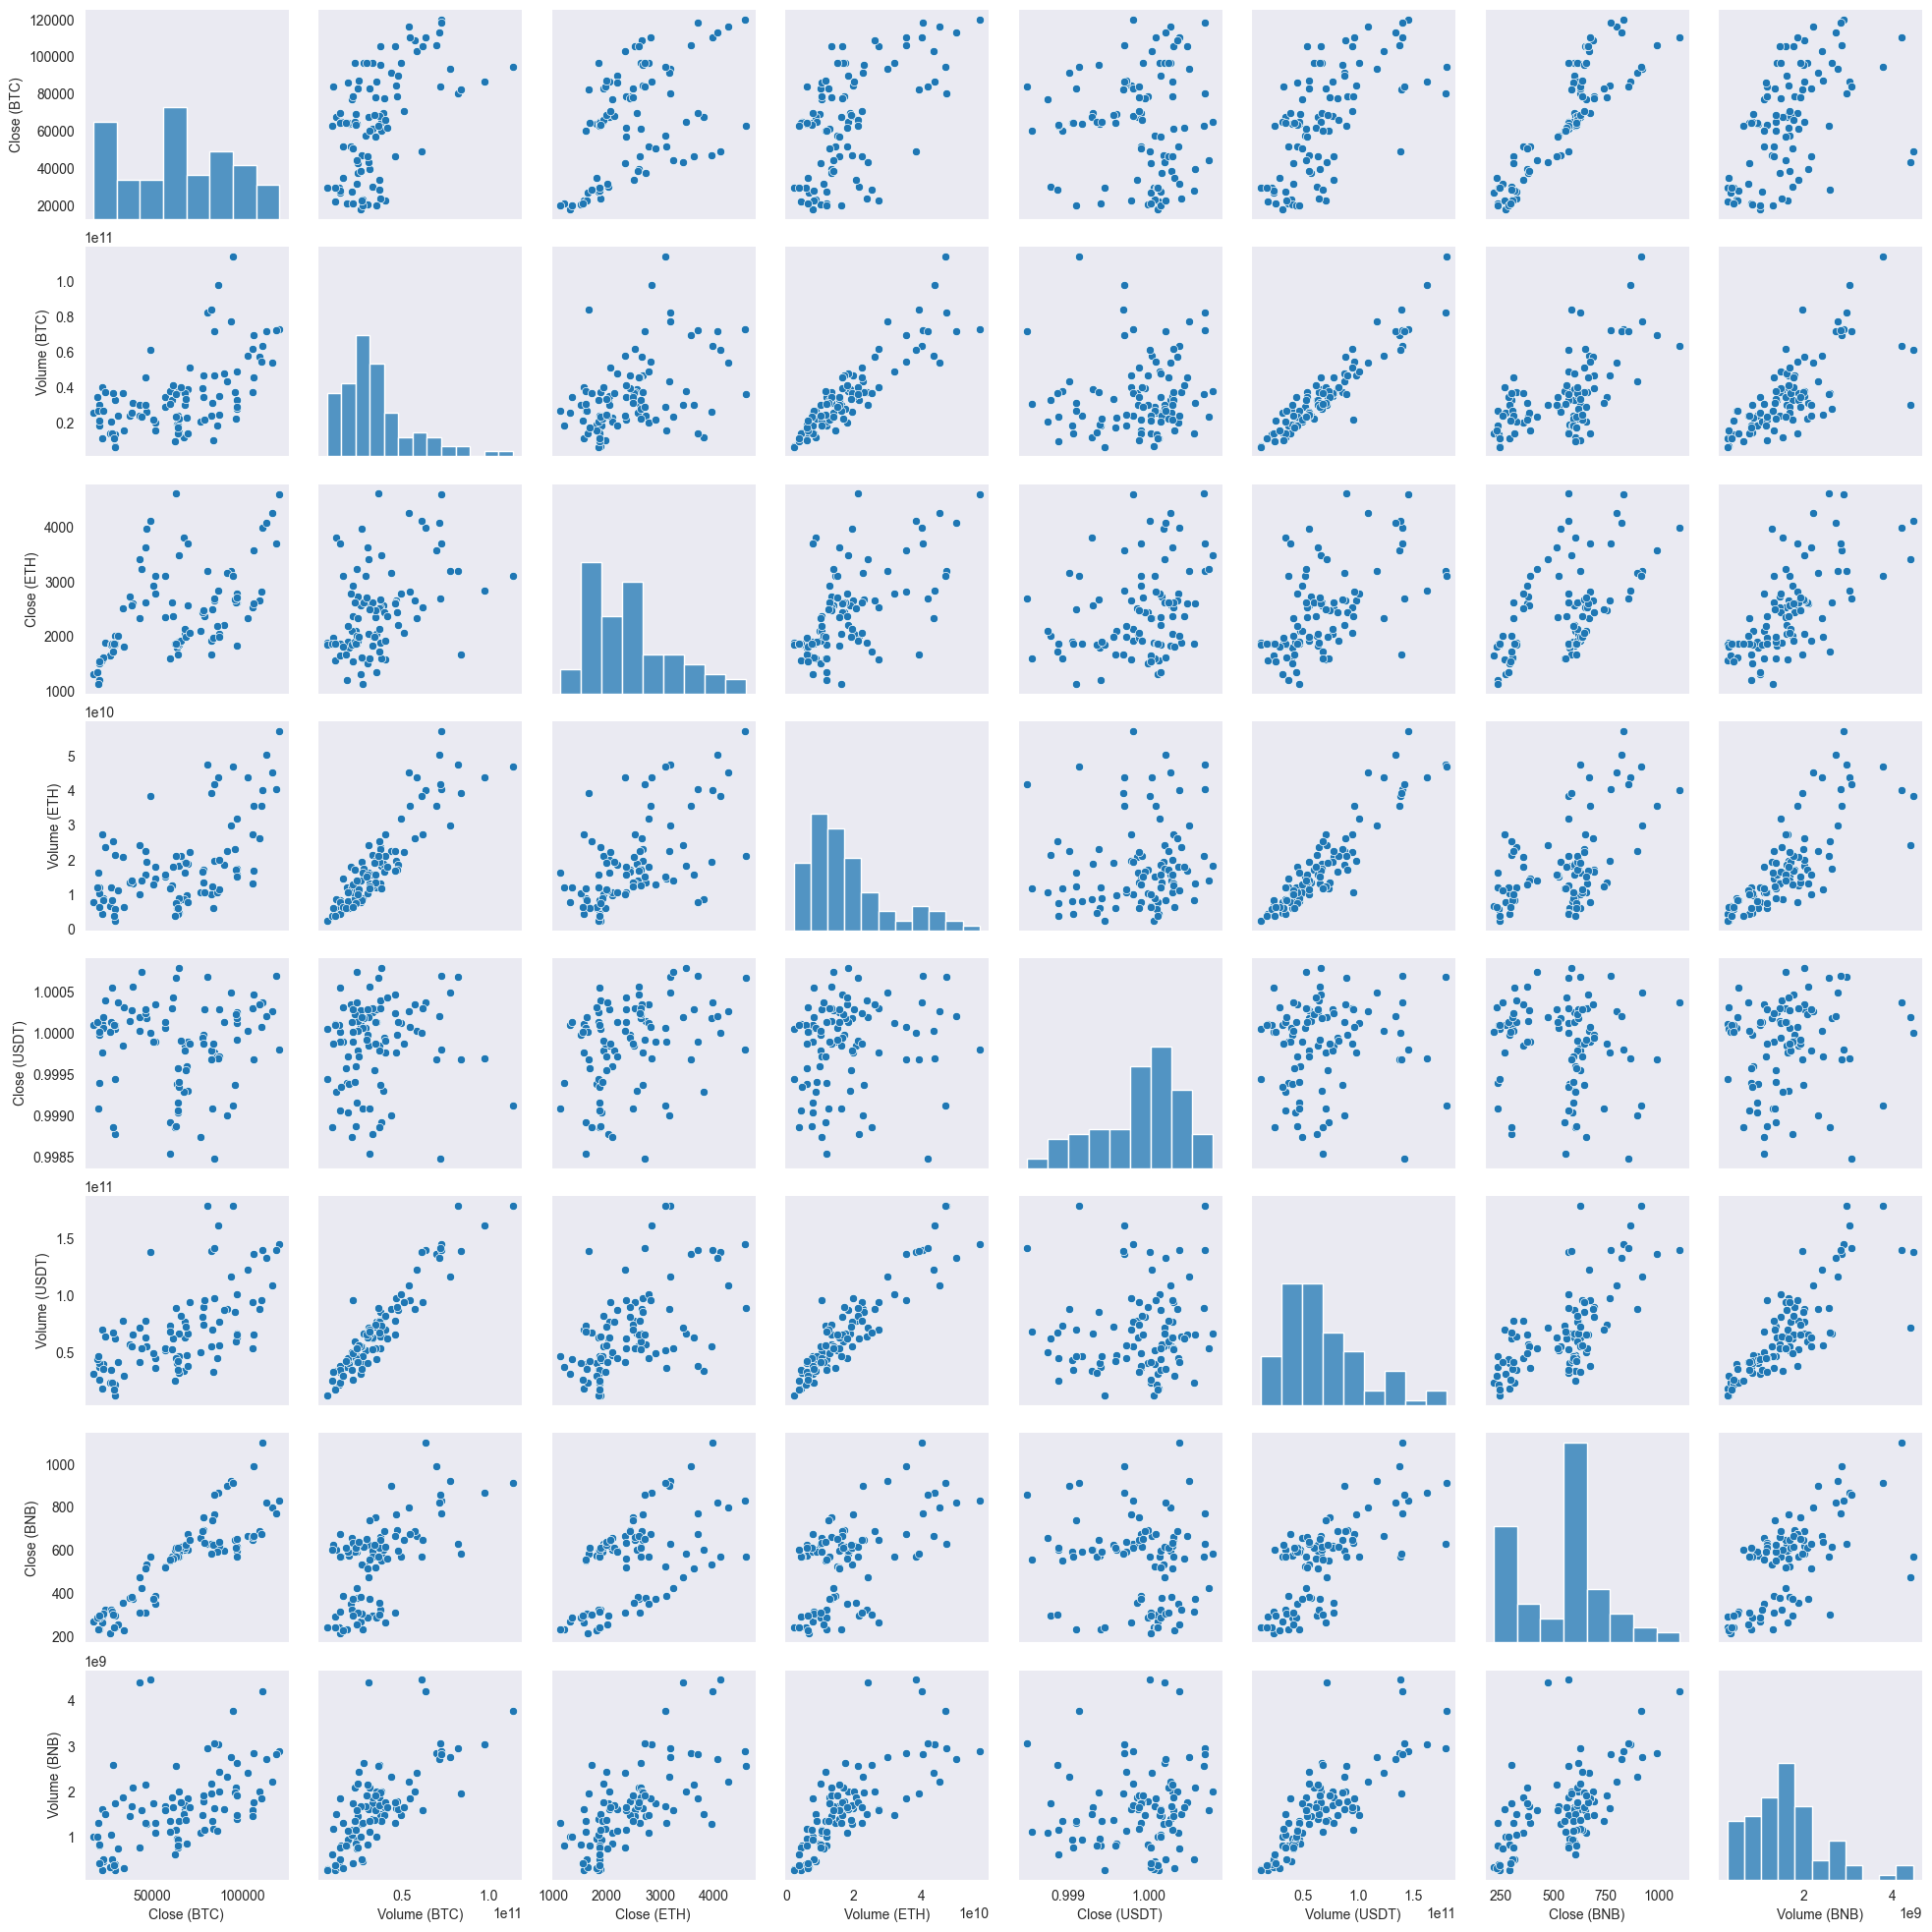

In [18]:
sns.pairplot(data.sample(n=100));

# Data pre-processing

In [19]:
X = data.drop(columns = ['Close (BTC)'], axis = 1)
Y = data.loc[:, 'Close (BTC)']

In [20]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-10-19 00:00:00+00:00,40471196346,3877.650879,15998757133,1.000117,62387883982,488.148865,1844483840
2021-10-20 00:00:00+00:00,40788955582,4155.992188,20338319988,0.999940,70187915900,501.020325,1890415594
2021-10-21 00:00:00+00:00,45908121370,4054.322754,28220661820,1.000022,84189482202,471.256927,3081793454
2021-10-22 00:00:00+00:00,38434082775,3970.181885,19432937968,0.999879,73919161798,478.643158,1962748496
2021-10-23 00:00:00+00:00,26882546034,4171.663574,14781537792,1.000823,55395032239,485.906433,1170864603


In [21]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-10-15 00:00:00+00:00,41979689877,2440.479980,18599863197,0.998809,87487791972,728.668152,1698751156
2026-10-16 00:00:00+00:00,26591693705,2419.767334,11773801739,0.998603,63342250194,720.894043,1309402321
2026-10-17 00:00:00+00:00,11535072090,2399.799072,5915110956,0.998715,35607186974,717.042175,1072065355
2026-10-18 00:00:00+00:00,18492770661,2408.741455,7944320489,0.998815,44956653893,722.255371,1130217153
2026-10-19 00:00:00+00:00,24875675648,2416.040039,9269184512,0.998960,55615311872,723.919983,1288933248


In [22]:
Y.sample(5)

Date
2024-08-16 00:00:00+00:00    58894.105469
2022-04-08 00:00:00+00:00    42287.664062
2021-11-04 00:00:00+00:00    61452.230469
2023-07-07 00:00:00+00:00    30342.265625
2022-08-28 00:00:00+00:00    19616.814453
Name: Close (BTC), dtype: float64

In [23]:
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                    test_size=0.2, 
                                                    random_state=0)

In [24]:
# Print the shapes of the resulting datasets
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1461, 7)
X_test shape: (366, 7)
y_train shape: (1461,)
y_test shape: (366,)


In [25]:
#SelectKBest
#SelectKBest is a feature selection method provided by scikit-learn (sklearn) that selects the top k features based on a specified scoring function.
#This function evaluates each feature independently and selects those that have the strongest relationship with the target variable.

#Parameters
#k: Specifies the number of top features to select. In your case, k=4 indicates that you want to select the top 4 features

from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:107: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [26]:
mask = fs.get_support()
selected_features = X.columns[mask]
print("Selected Features:", selected_features) 

Selected Features: Index(['Close (USDT)', 'Volume (USDT)', 'Close (BNB)', 'Volume (BNB)'], dtype='object')


In [27]:
X_train

array([[9.99773979e-01, 4.41267496e+10, 2.49593872e+02, 1.03098597e+09],
       [9.99170005e-01, 4.37891457e+10, 2.98397888e+02, 1.11521113e+09],
       [1.00021195e+00, 2.61179848e+10, 2.36134262e+02, 4.27457532e+08],
       ...,
       [9.99558985e-01, 1.24591006e+11, 6.17329773e+02, 1.59965762e+09],
       [1.00032902e+00, 2.91281299e+10, 3.28724213e+02, 9.12601797e+08],
       [9.99974012e-01, 1.45103405e+10, 2.14399948e+02, 2.64565518e+08]],
      shape=(1461, 4))

In [28]:
Y_train

Date
2022-07-16 00:00:00+00:00    21190.316406
2022-06-03 00:00:00+00:00    29704.390625
2023-06-26 00:00:00+00:00    30271.130859
2023-04-10 00:00:00+00:00    29652.980469
2026-04-07 00:00:00+00:00    71940.703125
                                 ...     
2024-02-01 00:00:00+00:00    43075.773438
2025-02-16 00:00:00+00:00    96175.031250
2026-04-29 00:00:00+00:00    75776.132812
2023-05-01 00:00:00+00:00    28091.568359
2023-09-03 00:00:00+00:00    25969.566406
Name: Close (BTC), Length: 1461, dtype: float64

In [29]:
#MinMaxScaler is a preprocessing method in scikit-learn that transforms features by scaling them to a specified range.
# It's often used when your data needs to be normalized within a specific range to ensure all features contribute equally to the analysis.
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
# implementation of 10 different regression algorithms using scikit-learn. Each algorithm is trained and evaluated on a sample dataset:

#Import Libraries and Generate Sample Data

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 119214283.98344953
R-squared: 0.8603129398487748

----- Ridge Regression -----
Mean Squared Error (MSE): 119910388.45919466
R-squared: 0.8594972927255791

----- Lasso Regression -----
Mean Squared Error (MSE): 119181468.6059739
R-squared: 0.8603513906405269

----- ElasticNet Regression -----
Mean Squared Error (MSE): 730951820.928845
R-squared: 0.1435211657026746

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 844120063.5451095
R-squared: 0.010918439038299144

----- Decision Tree Regression -----
Mean Squared Error (MSE): 108445937.57656263
R-squared: 0.8729305440653707

----- Random Forest Regression -----
Mean Squared Error (MSE): 55857174.538101666
R-squared: 0.9345504226602199

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 63863266.21798162
R-squared: 0.9251694376582978

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 59424582.30209835
R-squared: 0.93037038075364

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


----- Neural Network Regression (MLP) -----
Mean Squared Error (MSE): 559731607.4957293
R-squared: 0.3441451803237552

                             Model           MSE  R-squared
0                Linear Regression  1.192143e+08   0.860313
1                 Ridge Regression  1.199104e+08   0.859497
2                 Lasso Regression  1.191815e+08   0.860351
3            ElasticNet Regression  7.309518e+08   0.143521
4  Support Vector Regression (SVR)  8.441201e+08   0.010918
5         Decision Tree Regression  1.084459e+08   0.872931
6         Random Forest Regression  5.585717e+07   0.934550
7     Gradient Boosting Regression  6.386327e+07   0.925169
8   K-Nearest Neighbors Regression  5.942458e+07   0.930370
9  Neural Network Regression (MLP)  5.597316e+08   0.344145


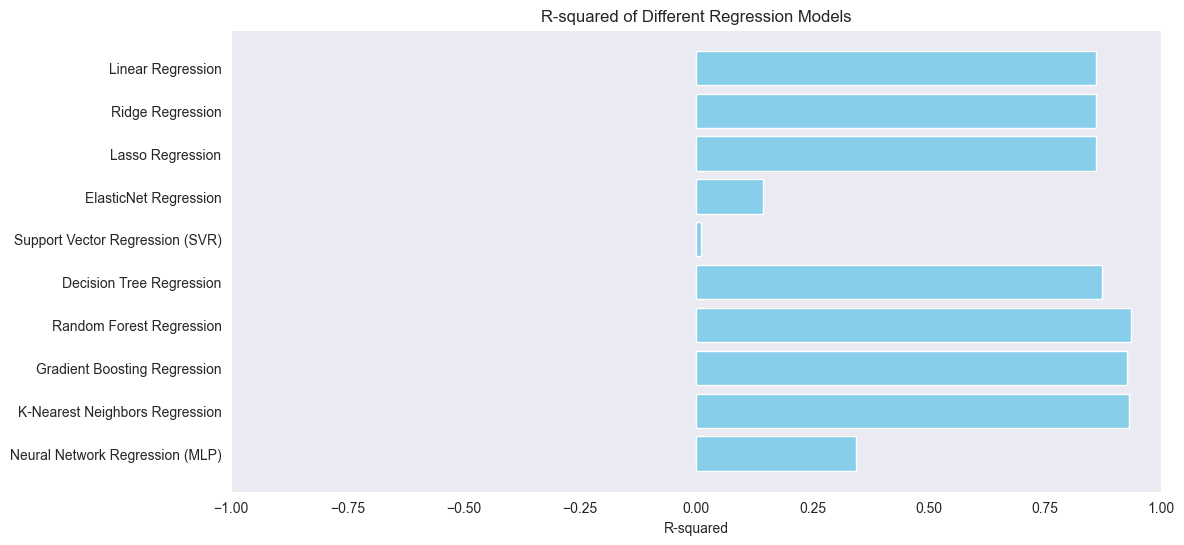

In [31]:

#Define Models and Perform Training and Evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'ElasticNet Regression': ElasticNet(alpha=1.0, l1_ratio=0.5),
    'Support Vector Regression (SVR)': SVR(kernel='rbf'),
    'Decision Tree Regression': DecisionTreeRegressor(),
    'Random Forest Regression': RandomForestRegressor(n_estimators=100),
    'Gradient Boosting Regression': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1),
    'K-Nearest Neighbors Regression': KNeighborsRegressor(n_neighbors=5),
    'Neural Network Regression (MLP)': MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam')
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    # Train the model
    model.fit(X_train, Y_train)

    # Predict on test set
    Y_pred = model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    # Store results
    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    # Print results
    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame for visualization
results_df = pd.DataFrame(results)
print(results_df)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()


 #Random Forest Regression is a powerful and versatile algorithm suitable for various regression tasks, offering robust performance and the ability to handle complex data relationships

In [32]:
#Saving the Model
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 53425603.97278053
Loaded Random Forest Regression - R-squared: 0.9373995690248209


In [33]:
import pickle
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# X_train / X_test were ALREADY scaled in cell 31. Do not scale again here.
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)
model_rf.fit(X_train, Y_train)

pickle.dump(model_rf, open('random_forest_model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))     # the scaler from cell 31

print("R2:", r2_score(Y_test, model_rf.predict(X_test)))
print("scaler min:", scaler.data_min_)
print("scaler max:", scaler.data_max_)

R2: 0.9373995690248209
scaler min: [0. 0. 0. 0.]
scaler max: [1. 1. 1. 1.]
